In [1]:
import importlib
import os
import sys

REPO = "/home/hey4/rich_tde"
sys.path.insert(0, os.path.join(REPO, "dev"))
os.environ["MPLCONFIGDIR"] = os.path.join(REPO, ".cache", "matplotlib")

In [2]:
import dev

# isort: split
import matplotlib.pyplot as plt
import numpy as np
import unyt as u
from dev.datapaths import TDE_PARAMETERS
from scipy.optimize import minimize_scalar

%matplotlib inline

importlib.reload(dev)
print(f"Plotting style: {dev.__file__}")

FIGSIZE = (5, 4.5)
MODEL_TIME = u.unyt_array(np.linspace(0, 3, 1001), "dimensionless")
DATA = os.path.join(REPO, "data", "processed", "FallbackRate")
FIT_START = 0.5  # t/t_fb; equal weights in linear rate, no amplitude/time shift
CHI_GRID = np.linspace(0, 1, 1001)


def energy_loss_rate(chi, time, T, M_b, epsilon_c, cutoff=False):
    """Cap energy loss; optionally omit crossings after circularization, f=1."""
    if chi == 0:
        n = np.arange(1, int(time[-1] / T[0]) + 1)
        return (np.interp(time[:, None] / n, T, M_b, left=0, right=0) / n).sum(axis=1)
    delta = chi * epsilon_c
    n_max = int(time[-1] / min(T[0], epsilon_c ** (-1.5)))
    edges = epsilon_c - np.arange(n_max) * delta
    transitions = edges[edges > 0] ** (-1.5)
    transitions = transitions[(transitions > T[0]) & (transitions < T[-1])]
    T0 = np.unique(np.concatenate((T, transitions)))
    epsilon_0 = T0 ** (-2 / 3)
    already_deep = epsilon_0 >= epsilon_c
    t_n = T0.copy()
    rate = np.interp(time, T, M_b, left=0, right=0)
    for n in range(2, n_max + 1):
        if cutoff and (n - 1) * delta >= epsilon_c:
            break
        # Initially deeper bins keep their original period; do not add energy.
        epsilon_k = np.where(
            already_deep,
            epsilon_0,
            np.minimum(epsilon_0 + (n - 1) * delta, epsilon_c),
        )
        T_k = epsilon_k ** (-1.5)
        t_n += T_k
        if t_n[0] > time[-1]:
            break
        active = (time >= t_n[0]) & (time <= t_n[-1])
        # Invert the continuous arrival map, then evaluate the piecewise Jacobian.
        original_period = np.interp(time[active], t_n, T0)
        binding = original_period ** (-2 / 3)
        J_n = np.full_like(original_period, n)
        shallow = binding < epsilon_c
        k = np.arange(1, min(n - 1, int(np.ceil(1 / chi))) + 1)
        post_loss = binding[shallow, None] + k * delta
        J_n[shallow] = 1 + np.where(
            post_loss < epsilon_c, (binding[shallow, None] / post_loss) ** 2.5, 0
        ).sum(axis=1)
        contribution = np.interp(original_period, T, M_b) / J_n
        if cutoff:
            # Count the final dissipating passage, then omit later circulation.
            contribution[binding + (n - 1) * delta >= epsilon_c] = 0
        rate[active] += contribution
    return rate

Plotting style: /home/hey4/rich_tde/dev/dev/__init__.py


## Fallback and repeated pericenter passages

### Ballistic return rate and the measured flux

Let $M=M_{\rm BH}$ and let $\varepsilon=-\epsilon_{\rm orb}>0$ denote the
**positive specific binding energy** of bound material. A Keplerian orbit has
$$
T(\varepsilon)=\frac{2\pi GM}{(2\varepsilon)^{3/2}},
\qquad
\varepsilon_0(T_0)=\frac12\left(\frac{2\pi GM}{T_0}\right)^{2/3}.
$$
We label a cohort by its original orbital period $T_0$ and approximate its
first-return time as $T_0$, measured from disruption. We use the orbital-energy
distribution measured near
$0.5t_{\rm fb}$ to assign these periods, without adding a snapshot-time offset.

Write the **ballistic mass-return rate** as $M_b(T_0)$, with units of mass per
time. If $g(\varepsilon)=dM/d\varepsilon$ is the bound-mass distribution, then
$$
M_b(T_0)
=g\!\left(\varepsilon_0(T_0)\right)
\left|\frac{d\varepsilon_0}{dT_0}\right|
=\frac{2\varepsilon_0(T_0)}{3T_0}\,
 g\!\left(\varepsilon_0(T_0)\right),
\qquad
 dM=M_b(T_0)\,dT_0.
$$
Thus $M_b(T_0)\,dT_0$ labels a cohort of material by its **initial** period.
The energy distribution is taken from
[the orbital-energy analysis](0.1-orbital-energy-spread.ipynb).

The red curve measures signed mass flux through a fixed window in the BH frame:
$$
\dot M_{\rm plane}(t)
=-\int_0^{5r_p}\int_{-5r_p}^{5r_p}
 \rho(x,0,z,t)\,v_y(x,0,z,t)\,dz\,dx.
$$
Downward crossings contribute positively and upward crossings negatively.
This includes the initial stellar passage and later circulation. The models
below approximate each returning orbit as giving one positive crossing of
this window per revolution.

### Repeated passages with no energy loss

Let $f$ be the fraction of a cohort retained after each passage. Its mass at
the $n$th passage is $f^{n-1}dM$; **all plotted models use $f=1$**.
If the period stays $T_0$, passage $n$ occurs at
$$
t_n=nT_0,\qquad dt=n\,dT_0.
$$
Consequently its contribution to the rate is
$f^{n-1}M_b(T_0)/n$, evaluated at $T_0=t/n$. Summing passages gives
$$
\boxed{
\dot M_{\rm fid}(t)
=\sum_{n=1}^{\infty}\frac{f^{n-1}}{n}\,M_b\!\left(\frac{t}{n}\right)
\quad (f=1\ \text{here}).
}
$$
The factor $1/n$ follows from conservation of cohort mass under the mapping
$T_0\mapsto t=nT_0$: a fixed interval of original periods arrives over an
$n$-times longer time interval on passage $n$.

### Fixed energy loss and the circularization scale

For nearly parabolic debris with specific angular momentum
$j^2\simeq2GMr_p$, a circular orbit with the same $j$ has
$r_c=j^2/(GM)\simeq2r_p$. Its binding energy defines our circularization scale,
$$
\varepsilon_c=\frac{GM}{2r_c}=\frac{GM}{4r_p},
\qquad
\delta\varepsilon=\chi\varepsilon_c.
$$
The parameter $\chi$ specifies a fixed specific energy loss per passage as a
fraction of this scale. Losing orbital energy increases the positive binding
energy. Energy changes at pericenter; motion between passages is approximated
as Keplerian. We adopt one common $r_p$ and circularization scale for the debris.

Let $\varepsilon_k$ be the binding energy **after $k$ passages**, with
$\varepsilon_0$ the original binding. Dissipation stops at $\varepsilon_c$:
$$
\boxed{
\varepsilon_k(T_0)
=\min\!\left[
 \varepsilon_0(T_0)+k\delta\varepsilon,
 \max\!\left(\varepsilon_0(T_0),\varepsilon_c\right)
\right].
}
$$
The outer maximum preserves the energy of material initially more bound than
$\varepsilon_c$, as in the current model. It does not force that material to
become less bound. For initially shallower material and $\chi>0$, the final
circularizing passage is
$$
N(T_0)=\left\lceil
 \frac{\varepsilon_c-\varepsilon_0(T_0)}{\delta\varepsilon}
\right\rceil.
$$
The last energy loss can be smaller than $\delta\varepsilon$.

### Orbital periods, arrival times, and the time Jacobian

The period **following passage $k$** is
$$
T_k(T_0)=\frac{2\pi GM}{[2\varepsilon_k(T_0)]^{3/2}}
=T_0\left[\frac{\varepsilon_0(T_0)}{\varepsilon_k(T_0)}\right]^{3/2}.
$$
The $n$th arrival occurs before its $n$th energy loss, so
$$
\boxed{
 t_n(T_0)=\sum_{k=0}^{n-1}T_k(T_0)
 =T_0\sum_{k=0}^{n-1}
 \left[\frac{\varepsilon_0(T_0)}{\varepsilon_k(T_0)}\right]^{3/2}.
}
$$
For example, $t_1=T_0$ and $t_2=T_0+T_1$. After circularization the period is
$T_c=2\pi GM/(2\varepsilon_c)^{3/2}$, and
$$
t_n=t_N+(n-N)T_c\qquad(n\geq N).
$$
The capped model therefore keeps producing crossings at the final period.
Initially deeper cohorts instead retain $T_k=T_0$ throughout.

To convert the ballistic rate into a rate at arrival time, define
$J_n(T_0)=dt_n/dT_0$. At fixed $\chi$ and $\varepsilon_c$,
$$
\frac{d\varepsilon_0}{dT_0}=-\frac{2\varepsilon_0}{3T_0},
\qquad
\frac{dT_k}{d\varepsilon_k}=-\frac{3T_k}{2\varepsilon_k}.
$$
Writing $D_k=d\varepsilon_k/d\varepsilon_0$, the chain rule gives
$$
\frac{dT_k}{dT_0}
=\frac{T_k}{T_0}\frac{\varepsilon_0}{\varepsilon_k}D_k
=\left(\frac{\varepsilon_0}{\varepsilon_k}\right)^{5/2}D_k,
\qquad
\boxed{
 J_n(T_0)=\sum_{k=0}^{n-1}
 \left(\frac{\varepsilon_0}{\varepsilon_k}\right)^{5/2}D_k.
}
$$
Away from the cap-transition points, $D_k=1$ before saturation and $D_k=0$
after saturation. For initially deeper cohorts $D_k=1$ for every $k$.
Equivalently, for $\varepsilon_0<\varepsilon_c$,
$$
J_n
=1+\sum_{k=1}^{n-1}
 \left(\frac{\varepsilon_0}{\varepsilon_0+k\delta\varepsilon}\right)^{5/2}
 \mathbf{1}_{\{\varepsilon_0+k\delta\varepsilon<\varepsilon_c\}}.
$$
For initially deeper material $J_n=n$. The first term always gives $J_n\geq1$,
so each arrival map is monotonic. After a shallow cohort circularizes,
$J_n=J_N$ on each smooth branch: adding the common period $T_c$ changes the
arrival time but adds no dependence on $T_0$.

### Full mass-crossing rates

At a given observation time $t$, define $T_0^{(n)}(t)$ by
$$
 t=t_n\!\left(T_0^{(n)}(t)\right).
$$
This is the **initial period of the cohort making its $n$th passage at $t$**.
Different values of $n$ generally select different cohorts. A term contributes
only when this solution lies in the initial-period support $\mathcal T$ of $M_b$.
Let $\mathcal N(t)$ denote the passage numbers with such a solution.

Let $C_n(T_0)$ indicate whether a passage is counted. Conservation of mass gives
$$
\dot M_n(t)\,dt
=f^{n-1}C_n(T_0)M_b(T_0)\,dT_0,
\qquad dt=J_n(T_0)\,dT_0.
$$
Therefore the complete expression is
$$
\boxed{
\dot M(t;\chi,f)
=\sum_{n\in\mathcal N(t)}
\left[
 \frac{f^{n-1}C_n(T_0)M_b(T_0)}
 {\displaystyle\sum_{k=0}^{n-1}
  \left[\frac{\varepsilon_0(T_0)}{\varepsilon_k(T_0)}\right]^{5/2}D_k(T_0)}
\right]_{T_0=T_0^{(n)}(t)}.
}
$$
The two loss models differ in the counting factor:

- **Loss capped:** $C_n=1$ for every passage. Gas remains in the mass-crossing
  rate after its energy stops changing.
- **Circularization cutoff:** include the final circularizing passage, then
  omit later circulation. For $\chi>0$ the convention used here is
  $$
  C_n^{\rm cut}(T_0)=
  \begin{cases}
  1, & n=1,\\
  \mathbf{1}_{\{\varepsilon_0(T_0)+(n-1)\delta\varepsilon<\varepsilon_c\}},
      & n\geq2.
  \end{cases}
  $$
  For initially shallow cohorts this is precisely $1\leq n\leq N(T_0)$.
  Every first arrival is retained, including the small initially deeper tail.

In compact form, the two plotted rates are
$$
\boxed{
\begin{aligned}
\dot M_{\rm cap}(t;\chi)
 &=\sum_{n\in\mathcal N(t)}
   \left[\frac{M_b(T_0)}{J_n(T_0)}\right]_{T_0=T_0^{(n)}(t)},\\[4pt]
\dot M_{\rm cut}(t;\chi)
 &=\sum_{n\in\mathcal N(t)}
   \left[\frac{C_n^{\rm cut}(T_0)M_b(T_0)}{J_n(T_0)}\right]_{T_0=T_0^{(n)}(t)}.
\end{aligned}
}
$$
Here $f=1$. With no loss, $T_k=T_0$, $t_n=nT_0$, and $J_n=n$, recovering the
fiducial expression. At exactly $\chi=0$ both models use that no-loss reference;
the positive-$\chi$ rule excluding later passages of initially deeper gas is
not applied in that special case.

### From a crossing rate to dissipation power

The red flux counts circulating gas whether or not it loses energy. The capped
model represents that counting, while the cutoff model selects the passages
associated with further dissipation. The energy actually dissipated per unit
mass on passage $n$ is
$$
\Delta\varepsilon_n(T_0)
=\varepsilon_n(T_0)-\varepsilon_{n-1}(T_0)
=\min\!\left[
 \delta\varepsilon,
 \max\!\left(0,\varepsilon_c-\varepsilon_{n-1}(T_0)\right)
\right].
$$
A future dissipation-power calculation would therefore use
$$
\boxed{
\dot E_{\rm diss}(t)
=\sum_{n\in\mathcal N(t)}
\left[
 \frac{f^{n-1}M_b(T_0)\,\Delta\varepsilon_n(T_0)}{J_n(T_0)}
\right]_{T_0=T_0^{(n)}(t)}.
}
$$
This becomes $\delta\varepsilon$ times the crossing rate only for passages that
each lose the full decrement. The final circularizing passage has a smaller
weight when needed; all subsequent passages, and initially deeper cohorts,
have zero weight. As a return branch reaches its cutoff, this energy weight
tends to zero even if the unweighted cutoff mass rate jumps. At the **same
$\chi$**, keeping or omitting the zero-dissipation crossings gives the same
$\dot E_{\rm diss}$. Radiative luminosity would additionally require the
fraction and timing of this dissipated energy that escapes as radiation.

### Relation to the plotted curves

The time normalization is
$$
t_{\rm fb}=\frac{2\pi GM}{(2\Delta\varepsilon)^{3/2}},
\qquad
\frac{T_k}{t_{\rm fb}}
=\left(\frac{\varepsilon_k}{\Delta\varepsilon}\right)^{-3/2},
$$
where $\Delta\varepsilon$ is the frozen-in tidal energy spread, distinct from
the per-passage loss $\delta\varepsilon$. For the $\beta=1$ runs here,
$\varepsilon_c/\Delta\varepsilon=r_p/(4R_\star)
=(M/M_\star)^{1/3}/4$.

We fit $\chi$ **independently for the capped and cutoff models** using the
measured flux at $t\geq0.5t_{\rm fb}$, with equal snapshot weights in linear rate
and no amplitude or time shift. Their displayed difference consequently
reflects both the counting prescription and their different fitted losses.
The models retain all mass ($f=1$) and include no accretion. The curves below
are mass-crossing rates; the dissipation-power expression above has not been
evaluated. The cached text-table headers record the simulation inputs, units,
frame conventions, and sampling settings.


## 1e4

In [3]:
RUN = "1e4"
flux_file = os.path.join(DATA, f"flux-{RUN}.txt")
energy_file = os.path.join(DATA, f"energy-{RUN}.txt")
flux = np.loadtxt(flux_file, ndmin=2)
energy = np.loadtxt(energy_file, ndmin=2)

time = u.unyt_array(flux[:, 2], "dimensionless")
mdot = u.unyt_array(flux[:, 3], "Msun/yr")
T = u.unyt_array(energy[:, 0], "dimensionless")
M_b = u.unyt_array(energy[:, 1], "Msun/yr")
print(f"{RUN}: {len(time)} snapshots; t/t_fb = {time[0]:.6f} to {time[-1]:.6f}")
print(f"Full-table rate range: {mdot.min():.6g} to {mdot.max():.6g}")
print(flux_file)
with open(energy_file) as handle:
    print(next(line[2:].strip() for line in handle if line.startswith("# snapshot=")))

1e4: 152 snapshots; t/t_fb = -0.008063 dimensionless to 2.174792 dimensionless
Full-table rate range: 0 Msun/yr to 1095.56 Msun/yr
/home/hey4/rich_tde/data/processed/FallbackRate/flux-1e4.txt
snapshot=54; requested_t_over_tfb=0.5; actual_t_over_tfb=0.50527110363340932


98 fitted snapshots; chi = 0.018320 (1.832%); f = 1
Relative RMS: fiducial = 11.22%; capped loss = 2.43%
Final rates: measured = 12.8056 Msun/yr; fiducial = 10.5148 Msun/yr; capped loss = 13.1601 Msun/yr
Best candidate minima (chi; relative RMS):
  0.018320 (1.832%); 2.43%
  0.000000 (0.000%); 11.22%
  1.000000 (100.000%); 1035.64%
Independent cutoff fit: chi = 0.018320 (1.832%); relative RMS = 2.43%
Final cutoff rate: 13.1592 Msun/yr
Best cutoff candidate minima (chi; relative RMS):
  0.018320 (1.832%); 2.43%
  0.000000 (0.000%); 11.22%
  0.902132 (90.213%); 18.05%
Capped-loss rate at 3 t_fb: 16.2091 Msun/yr
Circularization cutoff: rate at 3 t_fb = 16.2073 Msun/yr


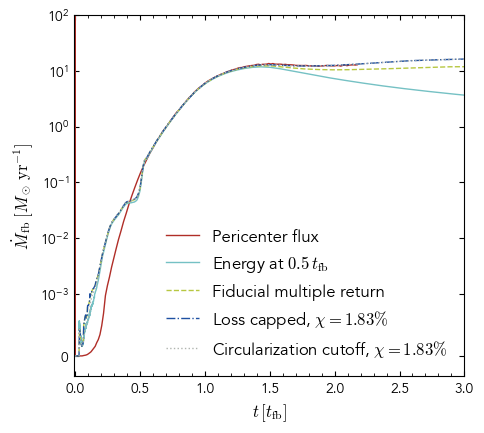

In [4]:
n = np.arange(1, int(time[-1] / T[0]) + 1)
fiducial = (np.interp(time[:, None] / n, T, M_b, left=0, right=0) / n).sum(axis=1)
mbh, mstar, _ = TDE_PARAMETERS[RUN]
# epsilon_c / Delta_epsilon = r_p / (4 R_star), for beta=1.
epsilon_c = u.unyt_quantity((mbh / mstar) ** (1 / 3) / 4, "dimensionless")
fit = time >= FIT_START
normalization = np.mean(mdot[fit] ** 2)


def loss(chi):
    model = energy_loss_rate(chi, time, T, M_b, epsilon_c)
    return float(np.mean((model[fit] - mdot[fit]) ** 2) / normalization)


loss_grid = np.array([loss(chi) for chi in CHI_GRID])
local_minima = (
    np.flatnonzero(
        (loss_grid[1:-1] <= loss_grid[:-2]) & (loss_grid[1:-1] < loss_grid[2:])
    )
    + 1
)
candidates = [CHI_GRID[0], CHI_GRID[-1]]
for index in local_minima:
    refined = minimize_scalar(
        loss, bounds=(CHI_GRID[index - 1], CHI_GRID[index + 1]), method="bounded"
    )
    candidates.append(min([CHI_GRID[index], refined.x], key=loss))
candidates.sort(key=loss)
chi = candidates[0]
loss_mdot = energy_loss_rate(chi, time, T, M_b, epsilon_c)
fiducial_rms = np.sqrt(np.mean((fiducial[fit] - mdot[fit]) ** 2) / normalization)
print(f"{fit.sum()} fitted snapshots; chi = {chi:.6f} ({100 * chi:.3f}%); f = 1")
print(
    f"Relative RMS: fiducial = {float(fiducial_rms):.2%}; capped loss = {np.sqrt(loss(chi)):.2%}"
)
print(
    f"Final rates: measured = {mdot[-1]:.4f}; fiducial = {fiducial[-1]:.4f}; capped loss = {loss_mdot[-1]:.4f}"
)

print("Best candidate minima (chi; relative RMS):")
for candidate in candidates[:3]:
    print(f"  {candidate:.6f} ({100 * candidate:.3f}%); {np.sqrt(loss(candidate)):.2%}")


def cutoff_loss(chi_cutoff):
    model = energy_loss_rate(chi_cutoff, time, T, M_b, epsilon_c, cutoff=True)
    return float(np.mean((model[fit] - mdot[fit]) ** 2) / normalization)


cutoff_grid = np.array([cutoff_loss(value) for value in CHI_GRID])
cutoff_minima = (
    np.flatnonzero(
        (cutoff_grid[1:-1] <= cutoff_grid[:-2]) & (cutoff_grid[1:-1] < cutoff_grid[2:])
    )
    + 1
)
cutoff_candidates = [CHI_GRID[0], CHI_GRID[-1]]
for index in cutoff_minima:
    refined_cutoff = minimize_scalar(
        cutoff_loss,
        bounds=(CHI_GRID[index - 1], CHI_GRID[index + 1]),
        method="bounded",
    )
    cutoff_candidates.append(min([CHI_GRID[index], refined_cutoff.x], key=cutoff_loss))
cutoff_candidates.sort(key=cutoff_loss)
chi_cutoff = cutoff_candidates[0]
cutoff_mdot = energy_loss_rate(chi_cutoff, time, T, M_b, epsilon_c, cutoff=True)
print(
    f"Independent cutoff fit: chi = {chi_cutoff:.6f} ({100 * chi_cutoff:.3f}%); relative RMS = {np.sqrt(cutoff_loss(chi_cutoff)):.2%}"
)
print(f"Final cutoff rate: {cutoff_mdot[-1]:.4f}")
print("Best cutoff candidate minima (chi; relative RMS):")
for candidate in cutoff_candidates[:3]:
    print(
        f"  {candidate:.6f} ({100 * candidate:.3f}%); {np.sqrt(cutoff_loss(candidate)):.2%}"
    )

n_plot = np.arange(1, int(MODEL_TIME[-1] / T[0]) + 1)
fiducial_plot = (
    np.interp(MODEL_TIME[:, None] / n_plot, T, M_b, left=0, right=0) / n_plot
).sum(axis=1)
loss_plot = energy_loss_rate(chi, MODEL_TIME, T, M_b, epsilon_c)
cutoff_plot = energy_loss_rate(chi_cutoff, MODEL_TIME, T, M_b, epsilon_c, cutoff=True)
print(f"Capped-loss rate at 3 t_fb: {loss_plot[-1]:.4f}")
print(f"Circularization cutoff: rate at 3 t_fb = {cutoff_plot[-1]:.4f}")

fig, ax = plt.subplots(figsize=FIGSIZE)
ax.plot(time, mdot, label="Pericenter flux")
ax.plot(T, M_b, label=r"Energy at $0.5\,t_{\rm fb}$")
ax.plot(MODEL_TIME, fiducial_plot, "--", label="Fiducial multiple return")
ax.plot(MODEL_TIME, loss_plot, "-.", label=rf"Loss capped, $\chi={100 * chi:.2f}\%$")
ax.plot(
    MODEL_TIME,
    cutoff_plot,
    ":",
    label=rf"Circularization cutoff, $\chi={100 * chi_cutoff:.2f}\%$",
)
ax.set_yscale("symlog", linthresh=1e-3)
ax.set(
    xlabel=r"$t\,[t_{\rm fb}]$",
    ylabel=r"$\dot M_{\rm fb}\;[M_\odot\,\mathrm{yr}^{-1}]$",
    xlim=(time[0], 3),
)
ax.set_ylim(top=1e2)
ax.legend()
fig.tight_layout()
plt.show()

## 1e5

In [5]:
RUN = "1e5"
flux_file = os.path.join(DATA, f"flux-{RUN}.txt")
energy_file = os.path.join(DATA, f"energy-{RUN}.txt")
flux = np.loadtxt(flux_file, ndmin=2)
energy = np.loadtxt(energy_file, ndmin=2)

time = u.unyt_array(flux[:, 2], "dimensionless")
mdot = u.unyt_array(flux[:, 3], "Msun/yr")
T = u.unyt_array(energy[:, 0], "dimensionless")
M_b = u.unyt_array(energy[:, 1], "Msun/yr")
print(f"{RUN}: {len(time)} snapshots; t/t_fb = {time[0]:.6f} to {time[-1]:.6f}")
print(f"Full-table rate range: {mdot.min():.6g} to {mdot.max():.6g}")
print(flux_file)
with open(energy_file) as handle:
    print(next(line[2:].strip() for line in handle if line.startswith("# snapshot=")))

1e5: 208 snapshots; t/t_fb = -0.003207 dimensionless to 1.066808 dimensionless
Full-table rate range: 0 Msun/yr to 1.03852e+06 Msun/yr
/home/hey4/rich_tde/data/processed/FallbackRate/flux-1e5.txt
snapshot=142; requested_t_over_tfb=0.5; actual_t_over_tfb=0.49754557039845027


65 fitted snapshots; chi = 0.107207 (10.721%); f = 1
Relative RMS: fiducial = 27.34%; capped loss = 11.53%
Final rates: measured = 3.4458 Msun/yr; fiducial = 2.5047 Msun/yr; capped loss = 3.8402 Msun/yr
Best candidate minima (chi; relative RMS):
  0.107207 (10.721%); 11.53%
  0.000000 (0.000%); 27.34%
  1.000000 (100.000%); 545.27%
Independent cutoff fit: chi = 0.108024 (10.802%); relative RMS = 11.68%
Final cutoff rate: 3.8409 Msun/yr
Best cutoff candidate minima (chi; relative RMS):
  0.108024 (10.802%); 11.68%
  0.129830 (12.983%); 20.30%
  0.000000 (0.000%); 27.34%
Capped-loss rate at 3 t_fb: 236.4806 Msun/yr
Circularization cutoff: rate at 3 t_fb = 13.4700 Msun/yr


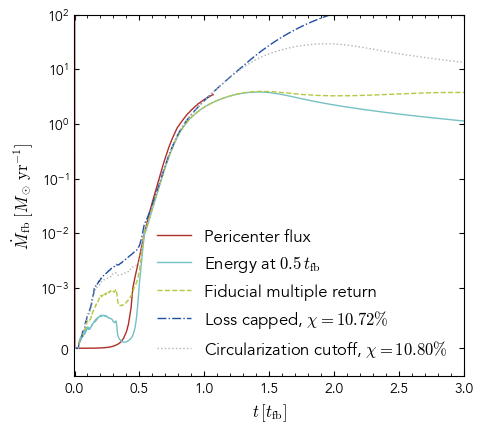

In [6]:
n = np.arange(1, int(time[-1] / T[0]) + 1)
fiducial = (np.interp(time[:, None] / n, T, M_b, left=0, right=0) / n).sum(axis=1)
mbh, mstar, _ = TDE_PARAMETERS[RUN]
# epsilon_c / Delta_epsilon = r_p / (4 R_star), for beta=1.
epsilon_c = u.unyt_quantity((mbh / mstar) ** (1 / 3) / 4, "dimensionless")
fit = time >= FIT_START
normalization = np.mean(mdot[fit] ** 2)


def loss(chi):
    model = energy_loss_rate(chi, time, T, M_b, epsilon_c)
    return float(np.mean((model[fit] - mdot[fit]) ** 2) / normalization)


loss_grid = np.array([loss(chi) for chi in CHI_GRID])
local_minima = (
    np.flatnonzero(
        (loss_grid[1:-1] <= loss_grid[:-2]) & (loss_grid[1:-1] < loss_grid[2:])
    )
    + 1
)
candidates = [CHI_GRID[0], CHI_GRID[-1]]
for index in local_minima:
    refined = minimize_scalar(
        loss, bounds=(CHI_GRID[index - 1], CHI_GRID[index + 1]), method="bounded"
    )
    candidates.append(min([CHI_GRID[index], refined.x], key=loss))
candidates.sort(key=loss)
chi = candidates[0]
loss_mdot = energy_loss_rate(chi, time, T, M_b, epsilon_c)
fiducial_rms = np.sqrt(np.mean((fiducial[fit] - mdot[fit]) ** 2) / normalization)
print(f"{fit.sum()} fitted snapshots; chi = {chi:.6f} ({100 * chi:.3f}%); f = 1")
print(
    f"Relative RMS: fiducial = {float(fiducial_rms):.2%}; capped loss = {np.sqrt(loss(chi)):.2%}"
)
print(
    f"Final rates: measured = {mdot[-1]:.4f}; fiducial = {fiducial[-1]:.4f}; capped loss = {loss_mdot[-1]:.4f}"
)

print("Best candidate minima (chi; relative RMS):")
for candidate in candidates[:3]:
    print(f"  {candidate:.6f} ({100 * candidate:.3f}%); {np.sqrt(loss(candidate)):.2%}")


def cutoff_loss(chi_cutoff):
    model = energy_loss_rate(chi_cutoff, time, T, M_b, epsilon_c, cutoff=True)
    return float(np.mean((model[fit] - mdot[fit]) ** 2) / normalization)


cutoff_grid = np.array([cutoff_loss(value) for value in CHI_GRID])
cutoff_minima = (
    np.flatnonzero(
        (cutoff_grid[1:-1] <= cutoff_grid[:-2]) & (cutoff_grid[1:-1] < cutoff_grid[2:])
    )
    + 1
)
cutoff_candidates = [CHI_GRID[0], CHI_GRID[-1]]
for index in cutoff_minima:
    refined_cutoff = minimize_scalar(
        cutoff_loss,
        bounds=(CHI_GRID[index - 1], CHI_GRID[index + 1]),
        method="bounded",
    )
    cutoff_candidates.append(min([CHI_GRID[index], refined_cutoff.x], key=cutoff_loss))
cutoff_candidates.sort(key=cutoff_loss)
chi_cutoff = cutoff_candidates[0]
cutoff_mdot = energy_loss_rate(chi_cutoff, time, T, M_b, epsilon_c, cutoff=True)
print(
    f"Independent cutoff fit: chi = {chi_cutoff:.6f} ({100 * chi_cutoff:.3f}%); relative RMS = {np.sqrt(cutoff_loss(chi_cutoff)):.2%}"
)
print(f"Final cutoff rate: {cutoff_mdot[-1]:.4f}")
print("Best cutoff candidate minima (chi; relative RMS):")
for candidate in cutoff_candidates[:3]:
    print(
        f"  {candidate:.6f} ({100 * candidate:.3f}%); {np.sqrt(cutoff_loss(candidate)):.2%}"
    )

n_plot = np.arange(1, int(MODEL_TIME[-1] / T[0]) + 1)
fiducial_plot = (
    np.interp(MODEL_TIME[:, None] / n_plot, T, M_b, left=0, right=0) / n_plot
).sum(axis=1)
loss_plot = energy_loss_rate(chi, MODEL_TIME, T, M_b, epsilon_c)
cutoff_plot = energy_loss_rate(chi_cutoff, MODEL_TIME, T, M_b, epsilon_c, cutoff=True)
print(f"Capped-loss rate at 3 t_fb: {loss_plot[-1]:.4f}")
print(f"Circularization cutoff: rate at 3 t_fb = {cutoff_plot[-1]:.4f}")

fig, ax = plt.subplots(figsize=FIGSIZE)
ax.plot(time, mdot, label="Pericenter flux")
ax.plot(T, M_b, label=r"Energy at $0.5\,t_{\rm fb}$")
ax.plot(MODEL_TIME, fiducial_plot, "--", label="Fiducial multiple return")
ax.plot(MODEL_TIME, loss_plot, "-.", label=rf"Loss capped, $\chi={100 * chi:.2f}\%$")
ax.plot(
    MODEL_TIME,
    cutoff_plot,
    ":",
    label=rf"Circularization cutoff, $\chi={100 * chi_cutoff:.2f}\%$",
)
ax.set_yscale("symlog", linthresh=1e-3)
ax.set(
    xlabel=r"$t\,[t_{\rm fb}]$",
    ylabel=r"$\dot M_{\rm fb}\;[M_\odot\,\mathrm{yr}^{-1}]$",
    xlim=(time[0], 3),
)
ax.set_ylim(top=1e2)
ax.legend()
fig.tight_layout()
plt.show()

## 1e6

In [7]:
RUN = "1e6"
flux_file = os.path.join(DATA, f"flux-{RUN}.txt")
energy_file = os.path.join(DATA, f"energy-{RUN}.txt")
flux = np.loadtxt(flux_file, ndmin=2)
energy = np.loadtxt(energy_file, ndmin=2)

time = u.unyt_array(flux[:, 2], "dimensionless")
mdot = u.unyt_array(flux[:, 3], "Msun/yr")
T = u.unyt_array(energy[:, 0], "dimensionless")
M_b = u.unyt_array(energy[:, 1], "Msun/yr")
print(f"{RUN}: {len(time)} snapshots; t/t_fb = {time[0]:.6f} to {time[-1]:.6f}")
print(f"Full-table rate range: {mdot.min():.6g} to {mdot.max():.6g}")
print(flux_file)
with open(energy_file) as handle:
    print(next(line[2:].strip() for line in handle if line.startswith("# snapshot=")))

1e6: 217 snapshots; t/t_fb = -0.000876 dimensionless to 1.155118 dimensionless
Full-table rate range: -3.49996e-13 Msun/yr to 2.72266e+06 Msun/yr
/home/hey4/rich_tde/data/processed/FallbackRate/flux-1e6.txt
snapshot=151; requested_t_over_tfb=0.5; actual_t_over_tfb=0.50119202446777156


66 fitted snapshots; chi = 0.050940 (5.094%); f = 1
Relative RMS: fiducial = 44.50%; capped loss = 14.08%
Final rates: measured = 2.0488 Msun/yr; fiducial = 1.0190 Msun/yr; capped loss = 2.2536 Msun/yr
Best candidate minima (chi; relative RMS):
  0.050940 (5.094%); 14.08%
  0.000000 (0.000%); 44.50%
  1.000000 (100.000%); 1839.07%
Independent cutoff fit: chi = 0.485409 (48.541%); relative RMS = 13.97%
Final cutoff rate: 2.0027 Msun/yr
Best cutoff candidate minima (chi; relative RMS):
  0.485409 (48.541%); 13.97%
  0.051409 (5.141%); 14.27%
  0.965193 (96.519%); 14.68%
Capped-loss rate at 3 t_fb: 245.1552 Msun/yr
Circularization cutoff: rate at 3 t_fb = 1.1026 Msun/yr


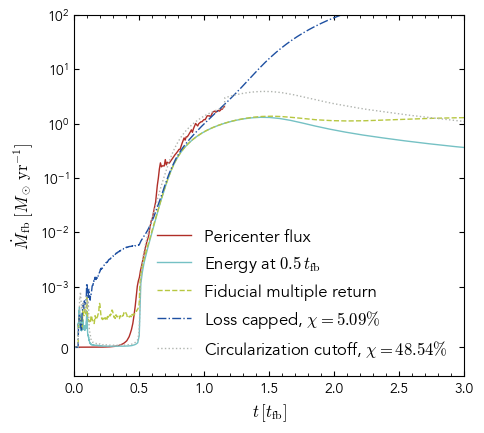

In [8]:
n = np.arange(1, int(time[-1] / T[0]) + 1)
fiducial = (np.interp(time[:, None] / n, T, M_b, left=0, right=0) / n).sum(axis=1)
mbh, mstar, _ = TDE_PARAMETERS[RUN]
# epsilon_c / Delta_epsilon = r_p / (4 R_star), for beta=1.
epsilon_c = u.unyt_quantity((mbh / mstar) ** (1 / 3) / 4, "dimensionless")
fit = time >= FIT_START
normalization = np.mean(mdot[fit] ** 2)


def loss(chi):
    model = energy_loss_rate(chi, time, T, M_b, epsilon_c)
    return float(np.mean((model[fit] - mdot[fit]) ** 2) / normalization)


loss_grid = np.array([loss(chi) for chi in CHI_GRID])
local_minima = (
    np.flatnonzero(
        (loss_grid[1:-1] <= loss_grid[:-2]) & (loss_grid[1:-1] < loss_grid[2:])
    )
    + 1
)
candidates = [CHI_GRID[0], CHI_GRID[-1]]
for index in local_minima:
    refined = minimize_scalar(
        loss, bounds=(CHI_GRID[index - 1], CHI_GRID[index + 1]), method="bounded"
    )
    candidates.append(min([CHI_GRID[index], refined.x], key=loss))
candidates.sort(key=loss)
chi = candidates[0]
loss_mdot = energy_loss_rate(chi, time, T, M_b, epsilon_c)
fiducial_rms = np.sqrt(np.mean((fiducial[fit] - mdot[fit]) ** 2) / normalization)
print(f"{fit.sum()} fitted snapshots; chi = {chi:.6f} ({100 * chi:.3f}%); f = 1")
print(
    f"Relative RMS: fiducial = {float(fiducial_rms):.2%}; capped loss = {np.sqrt(loss(chi)):.2%}"
)
print(
    f"Final rates: measured = {mdot[-1]:.4f}; fiducial = {fiducial[-1]:.4f}; capped loss = {loss_mdot[-1]:.4f}"
)

print("Best candidate minima (chi; relative RMS):")
for candidate in candidates[:3]:
    print(f"  {candidate:.6f} ({100 * candidate:.3f}%); {np.sqrt(loss(candidate)):.2%}")


def cutoff_loss(chi_cutoff):
    model = energy_loss_rate(chi_cutoff, time, T, M_b, epsilon_c, cutoff=True)
    return float(np.mean((model[fit] - mdot[fit]) ** 2) / normalization)


cutoff_grid = np.array([cutoff_loss(value) for value in CHI_GRID])
cutoff_minima = (
    np.flatnonzero(
        (cutoff_grid[1:-1] <= cutoff_grid[:-2]) & (cutoff_grid[1:-1] < cutoff_grid[2:])
    )
    + 1
)
cutoff_candidates = [CHI_GRID[0], CHI_GRID[-1]]
for index in cutoff_minima:
    refined_cutoff = minimize_scalar(
        cutoff_loss,
        bounds=(CHI_GRID[index - 1], CHI_GRID[index + 1]),
        method="bounded",
    )
    cutoff_candidates.append(min([CHI_GRID[index], refined_cutoff.x], key=cutoff_loss))
cutoff_candidates.sort(key=cutoff_loss)
chi_cutoff = cutoff_candidates[0]
cutoff_mdot = energy_loss_rate(chi_cutoff, time, T, M_b, epsilon_c, cutoff=True)
print(
    f"Independent cutoff fit: chi = {chi_cutoff:.6f} ({100 * chi_cutoff:.3f}%); relative RMS = {np.sqrt(cutoff_loss(chi_cutoff)):.2%}"
)
print(f"Final cutoff rate: {cutoff_mdot[-1]:.4f}")
print("Best cutoff candidate minima (chi; relative RMS):")
for candidate in cutoff_candidates[:3]:
    print(
        f"  {candidate:.6f} ({100 * candidate:.3f}%); {np.sqrt(cutoff_loss(candidate)):.2%}"
    )

n_plot = np.arange(1, int(MODEL_TIME[-1] / T[0]) + 1)
fiducial_plot = (
    np.interp(MODEL_TIME[:, None] / n_plot, T, M_b, left=0, right=0) / n_plot
).sum(axis=1)
loss_plot = energy_loss_rate(chi, MODEL_TIME, T, M_b, epsilon_c)
cutoff_plot = energy_loss_rate(chi_cutoff, MODEL_TIME, T, M_b, epsilon_c, cutoff=True)
print(f"Capped-loss rate at 3 t_fb: {loss_plot[-1]:.4f}")
print(f"Circularization cutoff: rate at 3 t_fb = {cutoff_plot[-1]:.4f}")

fig, ax = plt.subplots(figsize=FIGSIZE)
ax.plot(time, mdot, label="Pericenter flux")
ax.plot(T, M_b, label=r"Energy at $0.5\,t_{\rm fb}$")
ax.plot(MODEL_TIME, fiducial_plot, "--", label="Fiducial multiple return")
ax.plot(MODEL_TIME, loss_plot, "-.", label=rf"Loss capped, $\chi={100 * chi:.2f}\%$")
ax.plot(
    MODEL_TIME,
    cutoff_plot,
    ":",
    label=rf"Circularization cutoff, $\chi={100 * chi_cutoff:.2f}\%$",
)
ax.set_yscale("symlog", linthresh=1e-3)
ax.set(
    xlabel=r"$t\,[t_{\rm fb}]$",
    ylabel=r"$\dot M_{\rm fb}\;[M_\odot\,\mathrm{yr}^{-1}]$",
    xlim=(time[0], 3),
)
ax.set_ylim(top=1e2)
ax.legend()
fig.tight_layout()
plt.show()